In [ ]:
!pip install -q timm albumentations
!pip install torchmetrics


In [ ]:
import kagglehub
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import gc
import cv2
import timm
import random
import re

from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torchmetrics.classification import BinaryAUROC, BinaryAccuracy
from torch.amp import GradScaler, autocast

# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [ ]:
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
os.environ['KAGGLEHUB_CACHE'] = "./data"
path = kagglehub.competition_download("multimodal-cancer-classification-challenge-2026")


100%|██████████| 737M/737M [00:08<00:00, 90.8MB/s]

Extracting files...


In [ ]:
print(os.listdir(path))

['BF', 'sampleSubmission.csv', 'train.csv', 'FL']


In [ ]:
labels = pd.read_csv(os.path.join(path, 'train.csv'))
labels.head()

,Name,Diagnosis
0,pat_03_image_1.jpg,1
1,pat_03_image_2.jpg,1
2,pat_03_image_3.jpg,1
3,pat_03_image_4.jpg,1
4,pat_03_image_5.jpg,1


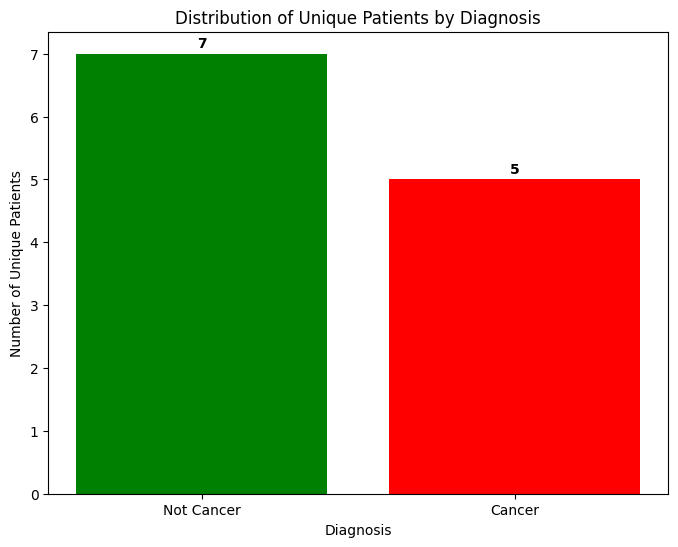

Total unique patients: 12
Diagnosis
Not Cancer    7
Cancer        5
Name: count, dtype: int64


In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# Extract Patient ID from the 'Name' column if not already present
# Pattern assumes 'pat_XX_image_YY.jpg'
labels['Patient'] = labels['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Get the diagnosis per patient (assuming one diagnosis per patient)
patient_diagnosis = labels.groupby('Patient')['Diagnosis'].first().reset_index()

# Count the number of patients for each diagnosis
diagnosis_counts = patient_diagnosis['Diagnosis'].value_counts().sort_index()

# Plotting
plt.figure(figsize=(8, 6))
colors = ['green', 'red']
labels_map = {0: 'Not Cancer', 1: 'Cancer'}
diagnosis_names = [labels_map[i] for i in diagnosis_counts.index]

plt.bar(diagnosis_names, diagnosis_counts.values, color=colors[:len(diagnosis_counts)])
plt.xlabel('Diagnosis')
plt.ylabel('Number of Unique Patients')
plt.title('Distribution of Unique Patients by Diagnosis')

# Add count labels on top of bars
for i, count in enumerate(diagnosis_counts.values):
    plt.text(i, count + 0.1, str(count), ha='center', fontweight='bold')

plt.show()

print(f"Total unique patients: {len(patient_diagnosis)}")
print(diagnosis_counts.rename(index=labels_map))

In [ ]:
num_patients = labels['Patient'].nunique()
print(f"There are {num_patients} unique patients in the dataset.")

There are 12 unique patients in the dataset.


Visualizing samples with labels from train.csv:


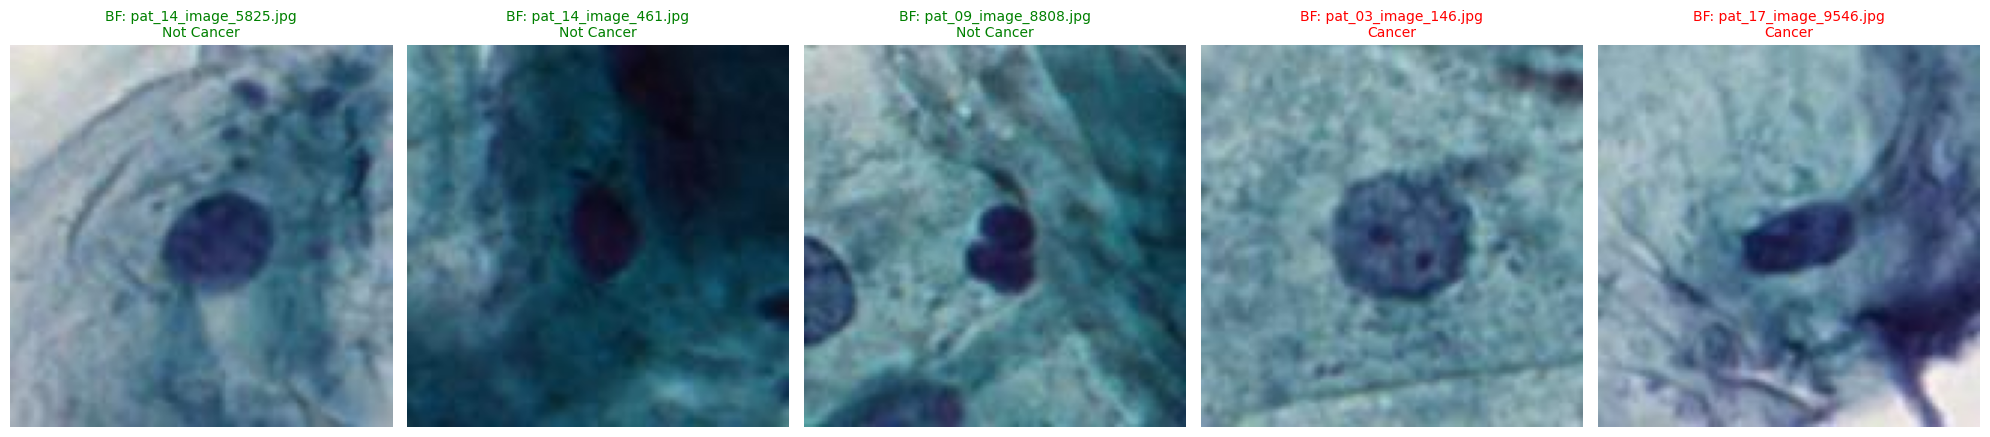

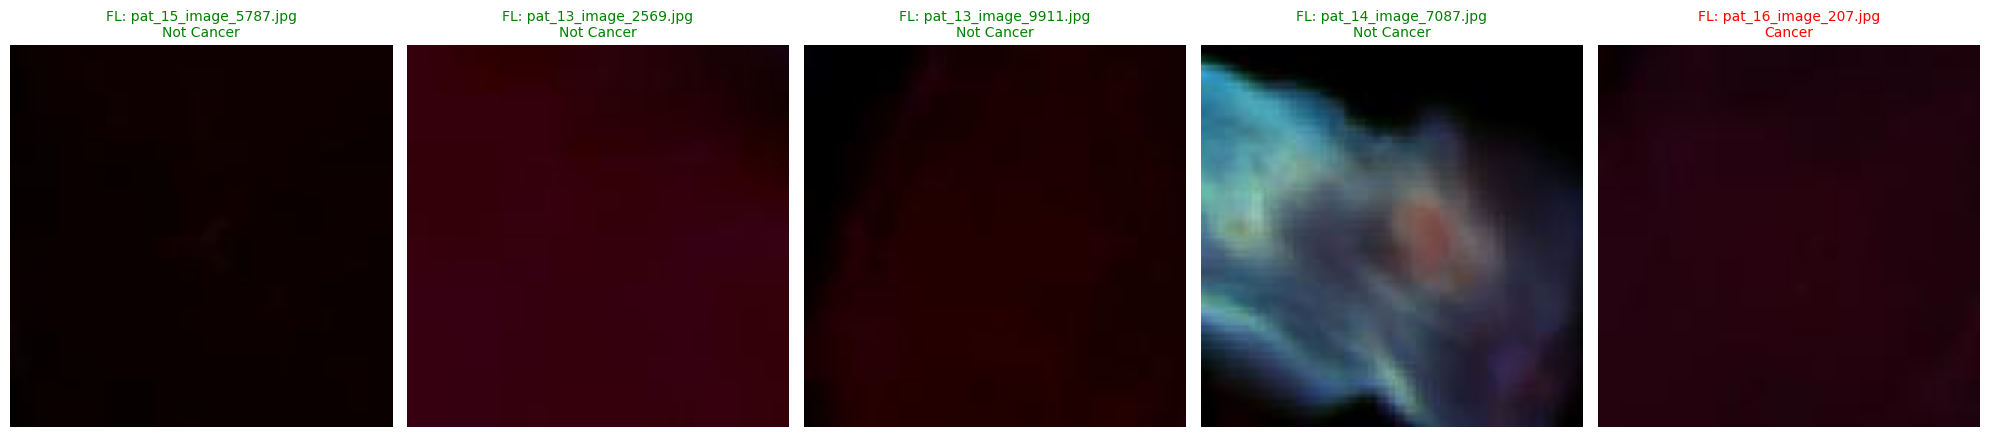

In [ ]:
# Load the latest labels from the competition directory
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Define paths for Bright Field and Fluorescence training images
BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')

# Mapping for human-readable titles
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

# Get lists of available image files
BF_Images_list = [f for f in os.listdir(BF_Images) if f.lower().endswith(('.jpg'))]
FL_Images_list = [f for f in os.listdir(FL_Images) if f.lower().endswith(('.jpg'))]

random.shuffle(BF_Images_list)
random.shuffle(FL_Images_list)

def plot_labeled_samples(img_list, base_path, title_prefix):
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))
    for i in range(5):
        img_name = img_list[i]
        img_path = os.path.join(base_path, img_name)
        img = cv2.imread(img_path)

        # Search for the diagnosis in the train_df based on filename
        match = train_df[train_df['Name'] == img_name]
        if not match.empty:
            label_val = match.iloc[0]['Diagnosis']
            label_text = diagnosis_map.get(label_val, 'Unknown')
        else:
            label_text = "Not Found in CSV"

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[i].imshow(img)
            title_color = 'red' if label_text == 'Cancer' else 'green' if label_text == 'Not Cancer' else 'black'
            ax[i].set_title(f"{title_prefix}: {img_name}\n{label_text}", color=title_color, fontsize=10)
        ax[i].axis("off")
    plt.tight_layout()
    plt.show()

print("Visualizing samples with labels from train.csv:")
plot_labeled_samples(BF_Images_list, BF_Images, "BF")
plot_labeled_samples(FL_Images_list, FL_Images, "FL")

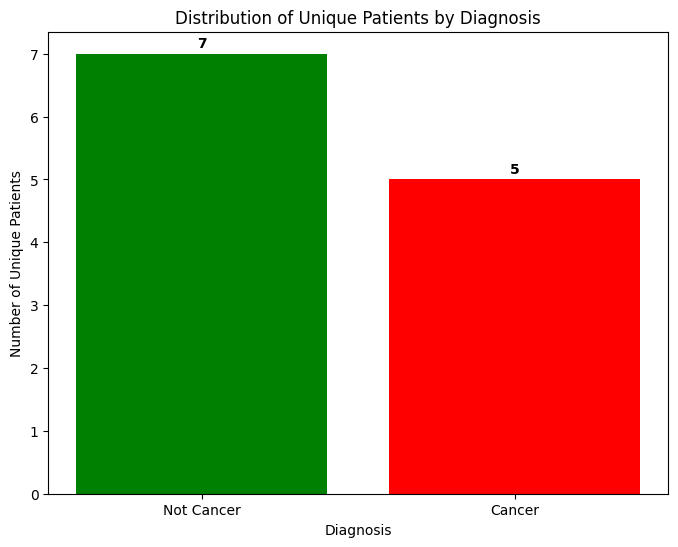

Total unique patients: 12


In [ ]:
# Using train_df consistently for data exploration
# Pattern assumes 'pat_XX_image_YY.jpg'
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Get the diagnosis per patient
patient_diagnosis = train_df.groupby('Patient')['Diagnosis'].first().reset_index()

# Count the number of patients for each diagnosis
diagnosis_counts = patient_diagnosis['Diagnosis'].value_counts().sort_index()

# Plotting
plt.figure(figsize=(8, 6))
colors = ['green', 'red']
labels_map = {0: 'Not Cancer', 1: 'Cancer'}
diagnosis_names = [labels_map[i] for i in diagnosis_counts.index]

plt.bar(diagnosis_names, diagnosis_counts.values, color=colors[:len(diagnosis_counts)])
plt.xlabel('Diagnosis')
plt.ylabel('Number of Unique Patients')
plt.title('Distribution of Unique Patients by Diagnosis')

for i, count in enumerate(diagnosis_counts.values):
    plt.text(i, count + 0.1, str(count), ha='center', fontweight='bold')

plt.show()

print(f"Total unique patients: {len(patient_diagnosis)}")

In [ ]:
num_patients = train_df['Patient'].nunique()
print(f"There are {num_patients} unique patients in the dataset.")

There are 12 unique patients in the dataset.


In [ ]:
# Load the labels and setup paths immediately after downloading
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Extract Patient ID immediately to ensure consistency across all downstream tasks
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

print(f"Loaded {len(train_df)} samples and extracted patient IDs.")

Loaded 114302 samples and extracted patient IDs.


In [ ]:
# Initialize GroupKFold based on the Patient ID column created in the loading step
gkf = GroupKFold(n_splits=3)
train_df['fold'] = -1

for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, train_df['Diagnosis'], groups=train_df['Patient'])):
    train_df.loc[val_idx, 'fold'] = fold

print(f"Fold distribution:\n{train_df['fold'].value_counts()}")
print(f"Unique patients per fold check:\n{train_df.groupby('fold')['Patient'].nunique()}")

Fold distribution:
fold
1    40000
0    40000
2    34302
Name: count, dtype: int64
Unique patients per fold check:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


In [ ]:
import pandas as pd

# Ensure we use the labels dataframe which has the patient and fold info
if 'labels' in globals() and 'fold' in labels.columns:
    df_to_check = labels
elif 'train_df' in globals() and 'fold' in train_df.columns:
    df_to_check = train_df
else:
    df_to_check = None

if df_to_check is not None:
    # Check if each patient belongs to only one fold
    patient_fold_counts = df_to_check.groupby('Patient')['fold'].nunique()
    is_valid_split = (patient_fold_counts == 1).all()

    # print(f"Is every patient assigned to exactly one fold? {is_valid_split}")

    # Display the mapping of Patient to Fold
    patient_to_fold = df_to_check.groupby(['Patient', 'fold']).size().reset_index(name='Image_Count')
    display(patient_to_fold)

    # Summary of how many patients are in each fold
    fold_summary = patient_to_fold.groupby('fold')['Patient'].count()
    print('\nNumber of patients per fold:')
    print(fold_summary)
else:
    print('Error: Could not find a dataframe with fold assignments. Please ensure the GroupKFold cell has been executed.')

,Patient,fold,Image_Count
0,pat_03,1,10000
1,pat_05,2,4302
2,pat_07,0,10000
3,pat_09,2,10000
4,pat_10,1,10000
5,pat_11,0,10000
6,pat_13,2,10000
7,pat_14,1,10000
8,pat_15,0,10000
9,pat_16,2,10000



Number of patients per fold:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


### Data Augmentations

In [ ]:
class MultimodalCancerDataset(Dataset):
    def __init__(self, df, bf_dir, fl_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']
        label = torch.tensor(self.df.loc[idx, 'Diagnosis'], dtype=torch.long)

        # Load BF Image
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL Image
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            # FIX: Pass both modalities through the transform simultaneously
            augmented = self.transform(image=bf_img, image_fl=fl_img)
            augmented_bf = augmented['image']
            augmented_fl = augmented['image_fl']

            # Stack modalities: Shape (6, H, W)
            return torch.cat([augmented_bf, augmented_fl], dim=0), label

        return (bf_img, fl_img), label

In [ ]:
train_transform = A.Compose([
    # A.Resize(128, 128),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10),
    ], p=0.3),
    # FIX: Reverted to 3-channel normalization
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
], additional_targets={'image_fl': 'image'}) # FIX: Bind the FL image to follow the exact same spatial transforms

val_transform = A.Compose([
    # A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
], additional_targets={'image_fl': 'image'})

train_ds = MultimodalCancerDataset(train_df[train_df['fold'] != 0], BF_Images, FL_Images, transform=train_transform)
valid_ds = MultimodalCancerDataset(train_df[train_df['fold'] == 0], BF_Images, FL_Images, transform=val_transform)

# Optimization: Increase num_workers and use pin_memory for faster GPU transfer
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train dataset size: {len(train_ds)}")
print(f"Validation dataset size: {len(valid_ds)}")

Train dataset size: 74302
Validation dataset size: 40000


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
# cafnet_val_transforms = A.Compose([
#     A.Resize(224, 224),
#     A.Normalize(mean=(0.485, 0.456, 0.406, 0.485, 0.456, 0.406),
#                 std=(0.229, 0.224, 0.225, 0.229, 0.224, 0.225)),
#     ToTensorV2(),
# ])

# # Update the validation dataset transform
# valid_ds.transform = cafnet_val_transforms
# print("Validation transforms (Resize + Normalize) applied to valid_ds.")

### Models

In [ ]:
class CrossAttention(nn.Module):
    def __init__(self, dim, num_heads=8, qkv_bias=False, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5

        self.q = nn.Linear(dim, dim, bias=qkv_bias)
        self.kv = nn.Linear(dim, dim * 2, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x_q, x_kv):
        B, N, C = x_q.shape
        _, M, _ = x_kv.shape

        q = self.q(x_q).reshape(B, N, self.num_heads, C // self.num_heads).permute(0, 2, 1, 3)
        kv = self.kv(x_kv).reshape(B, M, 2, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)
        return x

class CAFNet(nn.Module):
    def __init__(self, model_name='resnet18', pretrained=True):
        super(CAFNet, self).__init__()
        self.backbone_bf = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='')
        self.backbone_fl = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='')

        # --- FIX: Freeze the early layers of the pre-trained backbones ---
        for param in self.backbone_bf.parameters():
            param.requires_grad = False
        for param in self.backbone_fl.parameters():
            param.requires_grad = False

        # Optional: Unfreeze the last ResNet block (layer4) for fine-tuning
        for param in self.backbone_bf.layer4.parameters():
            param.requires_grad = True
        for param in self.backbone_fl.layer4.parameters():
            param.requires_grad = True
        # -----------------------------------------------------------------

        embed_dim = self.backbone_bf.num_features

        # Note: 49 assumes strictly 224x224 input images.
        # self.pos_embed_bf = nn.Parameter(torch.zeros(1, 49, embed_dim))
        # self.pos_embed_fl = nn.Parameter(torch.zeros(1, 49, embed_dim))
        self.pos_embed_bf = nn.Parameter(torch.zeros(1, 16, embed_dim))
        self.pos_embed_fl = nn.Parameter(torch.zeros(1, 16, embed_dim))

        self.bf_to_fl_attn = CrossAttention(dim=embed_dim, attn_drop=0.3, proj_drop=0.3)
        self.fl_to_bf_attn = CrossAttention(dim=embed_dim, attn_drop=0.3, proj_drop=0.3)

        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

        self.avgpool = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 2, 256),
            nn.GELU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.6), # Change this to 0.6 for stronger regularization
            nn.Linear(256, 1)
        )
        # Improved weight initialization for positional embeddings
        nn.init.trunc_normal_(self.pos_embed_bf, std=.02)
        nn.init.trunc_normal_(self.pos_embed_fl, std=.02)

    def forward(self, x):
        x_bf = x[:, :3, :, :]
        x_fl = x[:, 3:, :, :]

        feat_bf = self.backbone_bf(x_bf)
        feat_fl = self.backbone_fl(x_fl)

        B, C, H, W = feat_bf.shape

        # FIX: Safety check for image size mismatch
        # assert H * W == 49, f"Input size mismatch! Expected spatial size 49, got {H*W}. Ensure inputs are 224x224."
        assert H * W == 16, f"Input size mismatch! Expected spatial size 16, got {H*W}. Ensure inputs are 128x128."
        feat_bf = feat_bf.view(B, C, H*W).permute(0, 2, 1) + self.pos_embed_bf
        feat_fl = feat_fl.view(B, C, H*W).permute(0, 2, 1) + self.pos_embed_fl

        # --- FIX: Correct LayerNorm routing ---
        # Normalize each modality with its OWN dedicated LayerNorm
        normed_bf = self.norm1(feat_bf)
        normed_fl = self.norm2(feat_fl)

        # Cross-Attention: Inject FL info into BF, and BF info into FL
        fused_bf = feat_bf + self.bf_to_fl_attn(normed_bf, normed_fl)
        fused_fl = feat_fl + self.fl_to_bf_attn(normed_fl, normed_bf)
        # --------------------------------------

        out_bf = self.avgpool(fused_bf.transpose(1, 2)).flatten(1)
        out_fl = self.avgpool(fused_fl.transpose(1, 2)).flatten(1)

        out = torch.cat([out_bf, out_fl], dim=1)
        return self.classifier(out)

model_cafnet = CAFNet().to(device)
print("CAFNet initialized with Truncated Normal Positional Embeddings and frozen early layers.")

CAFNet initialized with Truncated Normal Positional Embeddings and frozen early layers.


### Resnet 50

### Baseline ResNet50 Model
This model uses a standard ResNet50 architecture but modifies the input layer to accept 6 channels (3 for BF and 3 for FL).

In [ ]:
class BaselineResNet50(nn.Module):
    def __init__(self, pretrained=True):
        super(BaselineResNet50, self).__init__()
        # Load base resnet50
        self.model = timm.create_model('resnet50', pretrained=pretrained, num_classes=1)

        # Modify the first conv layer to accept 6 channels
        # Standard ResNet50 has a 7x7 conv with stride 2 and 64 output filters
        old_conv = self.model.conv1
        self.model.conv1 = nn.Conv2d(6, old_conv.out_channels,
                                    kernel_size=old_conv.kernel_size,
                                    stride=old_conv.stride,
                                    padding=old_conv.padding,
                                    bias=old_conv.bias)

        # Initialize the new weights (first 3 channels use pretrained weights, next 3 are copies or random)
        if pretrained:
            with torch.no_grad():
                self.model.conv1.weight[:, :3, :, :] = old_conv.weight
                self.model.conv1.weight[:, 3:, :, :] = old_conv.weight # Initialize FL weights with BF weights

    def forward(self, x):
        return self.model(x)

model_resnet = BaselineResNet50(pretrained=True).to(device)
print("Baseline ResNet50 (6-channel input) initialized.")

Baseline ResNet50 (6-channel input) initialized.


### Training

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device, scaler):
    model.train()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    auroc_metric.reset()  # Ensure clean metrics

    for images, labels in tqdm(loader, desc="Training"):
        images, labels = images.to(device), labels.to(device).float().view(-1, 1)

        optimizer.zero_grad()
        with autocast("cuda"):
            outputs = model(images)

            # Label Smoothing: Only used for Training to prevent overconfidence
            smoothing = 0.1
            smoothed_labels = labels * (1 - smoothing) + 0.5 * smoothing
            loss = F.binary_cross_entropy_with_logits(outputs, smoothed_labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        auroc_metric.update(torch.sigmoid(outputs), labels.int())

    return total_loss / len(loader), auroc_metric.compute().item()

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    acc_metric = BinaryAccuracy().to(device)

    auroc_metric.reset() # Ensure clean metrics
    acc_metric.reset()

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device).float().view(-1, 1)
            with autocast("cuda"):
                outputs = model(images)
                # Use standard loss for validation - NO smoothing
                loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.sigmoid(outputs)
            auroc_metric.update(probs, labels.int())
            acc_metric.update(probs, labels.int())

    return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

In [ ]:
EPOCHS = 25 # Increased to give the regularized model time to learn
learning_rate = 1e-4

# --- FIX: Handle Class Imbalance ---
# Replace 'num_negative_samples' and 'num_positive_samples' with your actual counts
# weight = total_negative / total_positive
pos_weight_value = torch.tensor([3.0]).to(device) # Example: If you have 3x more Not Cancer than Cancer
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_value)
# -----------------------------------

# --- FIX: Filter parameters and increase weight decay ---
trainable_params = filter(lambda p: p.requires_grad, model_cafnet.parameters())
optimizer = AdamW(trainable_params, lr=learning_rate, weight_decay=5e-2)
# --------------------------------------------------------

scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

# Initialize GradScaler for AMP
scaler = GradScaler("cuda")

history = {'train_loss': [], 'train_auc': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}
best_val_auc = 0

for epoch in range(EPOCHS):
    train_loss, train_auc = train_one_epoch(model_cafnet, train_loader, optimizer, criterion, device, scaler)
    val_loss, val_auc, val_acc = validate(model_cafnet, valid_loader, criterion, device)

    scheduler.step(val_auc)

    history['train_loss'].append(train_loss)
    history['train_auc'].append(train_auc)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)
    history['val_acc'].append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_cafnet.state_dict(), 'best_model.pth')
        print("*** Best Model Saved ***")

Validation: 100%|██████████| 1250/1250 [02:03<00:00, 10.16it/s]



Epoch 1/25
Train Loss: 0.6038 | Train AUC: 0.9170
Val Loss: 0.5934 | Val AUC: 0.9047 | Val Acc: 0.8331
*** Best Model Saved ***


Validation: 100%|██████████| 1250/1250 [01:58<00:00, 10.57it/s]



Epoch 2/25
Train Loss: 0.4535 | Train AUC: 0.9543
Val Loss: 0.5900 | Val AUC: 0.9139 | Val Acc: 0.8241
*** Best Model Saved ***


Validation: 100%|██████████| 1250/1250 [02:01<00:00, 10.25it/s]



Epoch 3/25
Train Loss: 0.3971 | Train AUC: 0.9652
Val Loss: 0.9266 | Val AUC: 0.8392 | Val Acc: 0.7655


... (4 outputs left out)

Validation: 100%|██████████| 1250/1250 [01:49<00:00, 11.37it/s]



Epoch 6/25
Train Loss: 0.3108 | Train AUC: 0.9787
Val Loss: 1.1502 | Val AUC: 0.8008 | Val Acc: 0.7411


Training:  91%|█████████▏| 2120/2322 [04:47<00:27,  7.38it/s]


KeyboardInterrupt: 

### Test

In [ ]:
class MultimodalTestDataset(Dataset):
    def __init__(self, test_df, bf_dir, fl_dir, transform=None):
        self.df = test_df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']

        # Load BF
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            augmented_bf = self.transform(image=bf_img)['image']
            augmented_fl = self.transform(image=fl_img)['image']
            return torch.cat([augmented_bf, augmented_fl], dim=0), img_name
        else:
            # Ensure consistent 6-channel output even without transforms
            bf_tensor = torch.from_numpy(bf_img).permute(2, 0, 1).float() / 255.0
            fl_tensor = torch.from_numpy(fl_img).permute(2, 0, 1).float() / 255.0
            return torch.cat([bf_tensor, fl_tensor], dim=0), img_name

# Load sample submission to get test file names
test_df = pd.read_csv(os.path.join(path, 'sampleSubmission.csv'))

# Note: Assuming test images are in 'BF/test' and 'FL/test'
BF_Test = os.path.join(path, 'BF', 'test')
FL_Test = os.path.join(path, 'FL', 'test')

# Use val_transform for testing to ensure deterministic resizing and normalization
test_ds = MultimodalTestDataset(test_df, BF_Test, FL_Test, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

In [ ]:
model_cafnet.eval()
predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model_cafnet(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)



# Create submission dataframe
# submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
# submission.to_csv('submission_resnet_early_fahimv2.csv', index=False)
# print("Submission file saved as submission.csv")
# display(submission.head())

In [ ]:
# Load the best weights before inference
model_cafnet.load_state_dict(torch.load('best_model.pth'))
model_cafnet.eval()

predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        with autocast("cuda"):
            outputs = model_cafnet(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission.csv', index=False)
print("Submission file saved.")
display(submission.head())